In [1]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "analysis":
    PROJECT_ROOT = PROJECT_ROOT.parent

data_path = PROJECT_ROOT / "data" / "processed" / "athlete_events_clean.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("Olympic years:", df["Year"].min(), "to", df["Year"].max())
print("Unique athletes:", df["ID"].nunique())
print("Unique sports:", df["Sport"].nunique())
print("Unique events:", df["Event"].nunique())
print("Unique regions:", df["Region"].nunique())

Dataset shape: (269731, 16)
Olympic years: 1896 to 2016
Unique athletes: 135571
Unique sports: 66
Unique events: 765
Unique regions: 209


In [2]:
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

display(missing.sort_values("Missing Percentage", ascending=False))

,Missing Count,Missing Percentage
Medal,229959,85.25
Weight,61527,22.81
Height,58814,21.80
Age,9315,3.45
ID,0,0.00
Name,0,0.00
Sex,0,0.00
Team,0,0.00
NOC,0,0.00
Games,0,0.00


In [3]:
participation = (
    df.groupby(["Year", "Season"])
      .agg(
          Athlete_Entries=("ID", "size"),
          Unique_Athletes=("ID", "nunique"),
          Countries_Regions=("Region", "nunique"),
          Sports=("Sport", "nunique")
      )
      .reset_index()
      .sort_values(["Year", "Season"])
)

display(participation.head(15))

,Year,Season,Athlete_Entries,Unique_Athletes,Countries_Regions,Sports
0,1896,Summer,380,176,12,9
1,1900,Summer,1898,1224,31,20
2,1904,Summer,1301,650,14,18
3,1906,Summer,1733,841,20,13
4,1908,Summer,3069,2024,22,24
5,1912,Summer,4040,2409,29,17
6,1920,Summer,4292,2676,29,25
7,1924,Summer,5110,3256,45,20
8,1924,Winter,460,313,19,10
9,1928,Summer,4656,3247,46,17


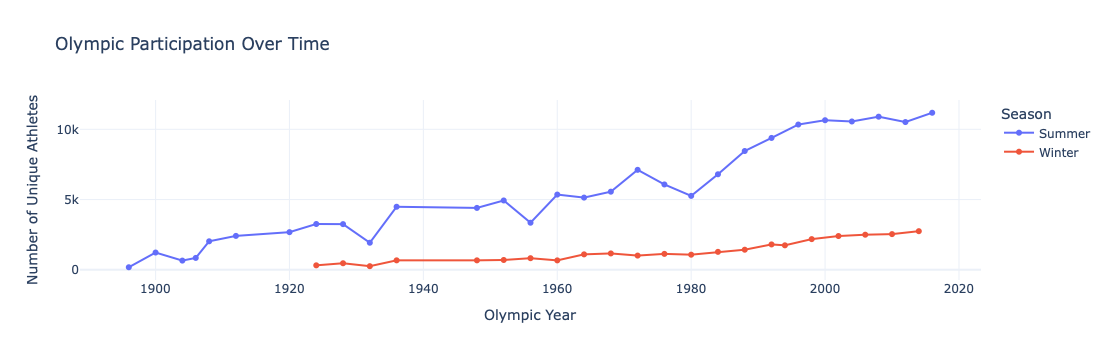

In [5]:
import plotly.express as px

fig = px.line(
    participation,
    x="Year",
    y="Unique_Athletes",
    color="Season",
    markers=True,
    title="Olympic Participation Over Time",
    labels={
        "Year": "Olympic Year",
        "Unique_Athletes": "Number of Unique Athletes",
        "Season": "Olympic Season"
    },
    hover_data=["Athlete_Entries", "Countries_Regions", "Sports"]
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified",
    legend_title_text="Season"
)

fig.show()

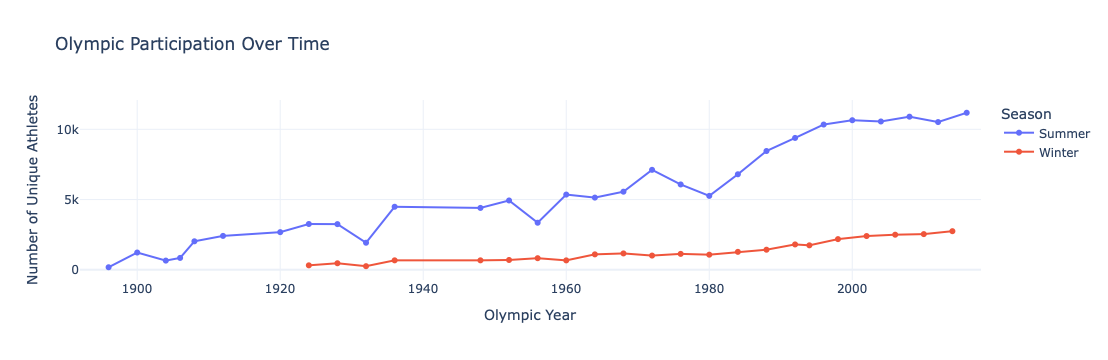

In [6]:
fig.update_xaxes(range=[1892, 2018])

In [7]:
# Keep only records with an actual medal
medal_df = df[df["Medal"].notna()].copy()

print("Medal-winning records:", len(medal_df))
print("\nMedal distribution:")
print(medal_df["Medal"].value_counts())

# Count medal records by region and medal type
medal_counts = (
    medal_df.groupby(["Region", "Medal"])
    .size()
    .unstack(fill_value=0)
)

# Add total medals and rank regions
medal_counts["Total"] = medal_counts.sum(axis=1)

medal_counts = medal_counts.sort_values(
    "Total", ascending=False
)

display(medal_counts.head(10))

Medal-winning records: 39772

Medal distribution:
Medal
Gold      13369
Bronze    13295
Silver    13108
Name: count, dtype: int64


Medal,Bronze,Gold,Silver,Total
Region,,,,
USA,1358,2638,1641,5637
Russia,1178,1599,1170,3947
Germany,1260,1301,1195,3756
UK,651,677,739,2067
France,666,499,602,1767
Italy,531,575,531,1637
Sweden,535,479,522,1536
Canada,451,463,438,1352
Australia,522,368,459,1349


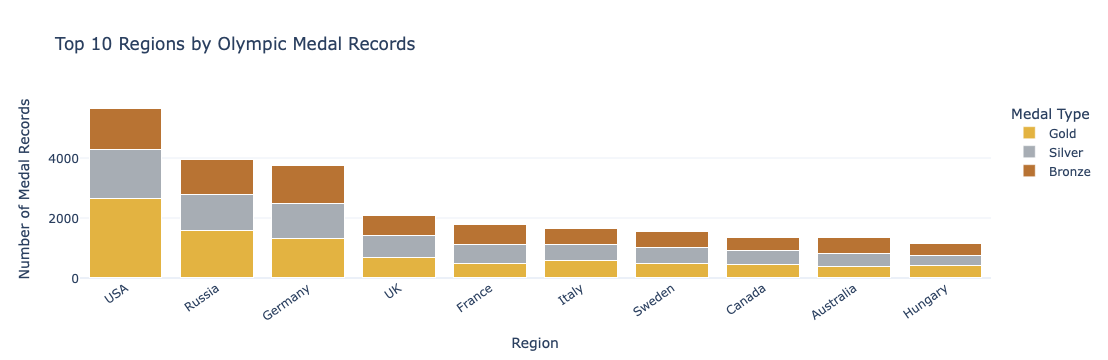

In [8]:
import plotly.express as px

# Select the top 10 regions by total medal records
top_10 = (
    medal_counts
    .head(10)
    .reset_index()
)

# Convert medal columns into long format for Plotly
top_10_long = top_10.melt(
    id_vars=["Region"],
    value_vars=["Gold", "Silver", "Bronze"],
    var_name="Medal Type",
    value_name="Medal Records"
)

fig = px.bar(
    top_10_long,
    x="Region",
    y="Medal Records",
    color="Medal Type",
    barmode="stack",
    title="Top 10 Regions by Olympic Medal Records",
    labels={
        "Region": "Region",
        "Medal Records": "Number of Medal Records",
        "Medal Type": "Medal Type"
    },
    category_orders={
        "Region": top_10["Region"].tolist(),
        "Medal Type": ["Gold", "Silver", "Bronze"]
    },
    color_discrete_map={
        "Gold": "#E3B341",
        "Silver": "#A7ADB4",
        "Bronze": "#B87333"
    }
)

fig.update_layout(
    template="plotly_white",
    xaxis_tickangle=-35,
    legend_title_text="Medal Type"
)

fig.show()

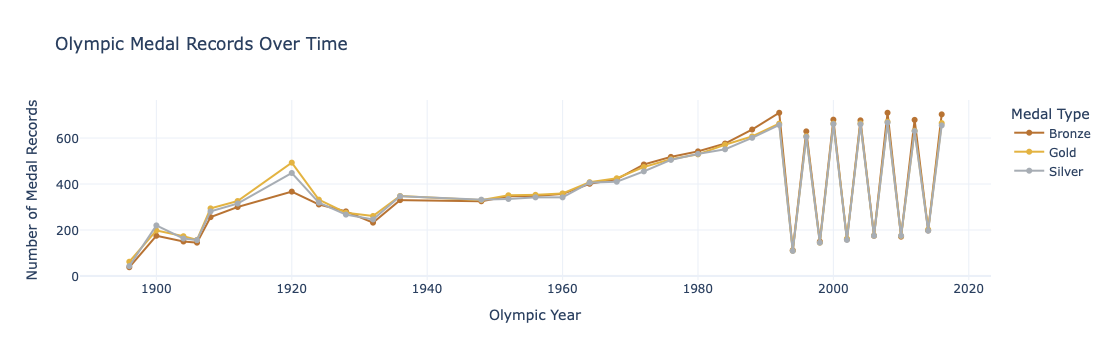

In [9]:
# Aggregate medal records by year and medal type
medals_by_year = (
    medal_df.groupby(["Year", "Medal"])
    .size()
    .reset_index(name="Medal Records")
)

import plotly.express as px

fig = px.line(
    medals_by_year,
    x="Year",
    y="Medal Records",
    color="Medal",
    markers=True,
    title="Olympic Medal Records Over Time",
    labels={
        "Year": "Olympic Year",
        "Medal Records": "Number of Medal Records",
        "Medal": "Medal Type"
    },
    color_discrete_map={
        "Gold": "#E3B341",
        "Silver": "#A7ADB4",
        "Bronze": "#B87333"
    }
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified"
)

fig.show()

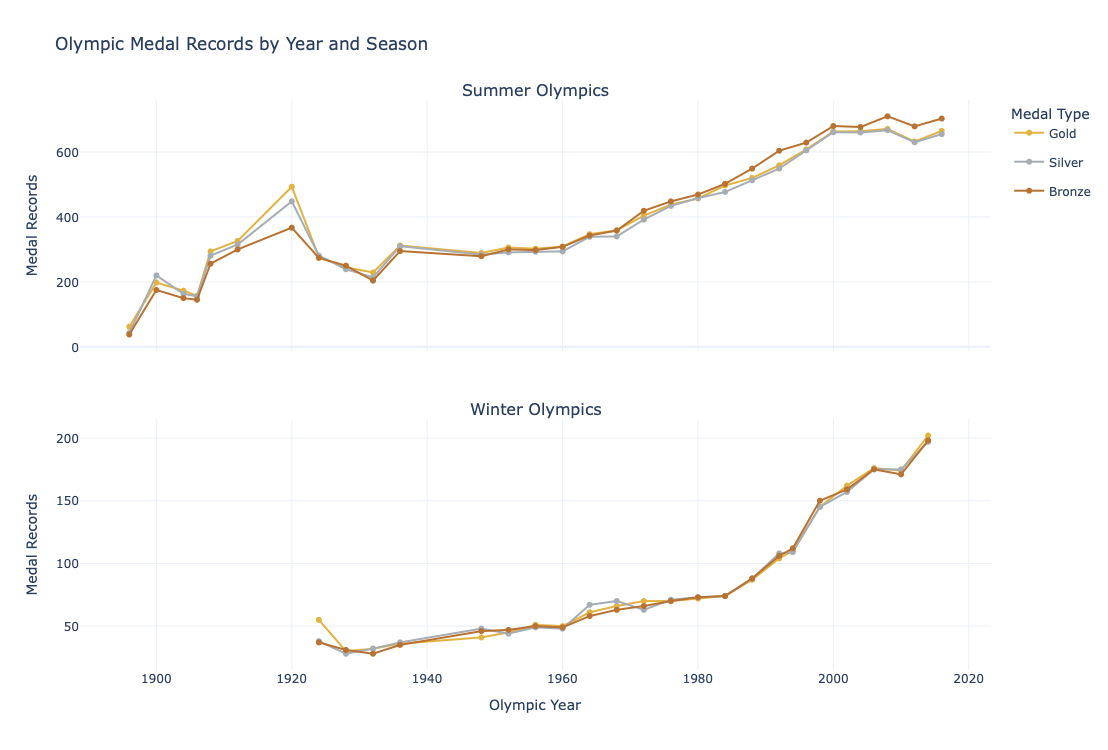

In [12]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=2,
    cols=1,
    subplot_titles=(
        "Summer Olympics",
        "Winter Olympics"
    ),
    shared_xaxes=True,
    vertical_spacing=0.12
)

medal_colors = {
    "Gold": "#E3B341",
    "Silver": "#A7ADB4",
    "Bronze": "#B87333"
}

for row, season in [(1, "Summer"), (2, "Winter")]:
    season_data = medals_by_year_season[
        medals_by_year_season["Season"] == season
    ]

    for medal in ["Gold", "Silver", "Bronze"]:
        medal_data = season_data[
            season_data["Medal"] == medal
        ]

        fig.add_trace(
            go.Scatter(
                x=medal_data["Year"],
                y=medal_data["Medal Records"],
                mode="lines+markers",
                name=medal,
                legendgroup=medal,
                showlegend=(row == 1),
                line=dict(color=medal_colors[medal]),
                hovertemplate=(
                    "Year: %{x}<br>"
                    "Medal records: %{y}<extra></extra>"
                )
            ),
            row=row,
            col=1
        )

fig.update_layout(
    title="Olympic Medal Records by Year and Season",
    template="plotly_white",
    height=750,
    hovermode="x unified",
    legend_title_text="Medal Type"
)

fig.update_xaxes(title_text="Olympic Year", row=2, col=1)
fig.update_yaxes(title_text="Medal Records", row=1, col=1)
fig.update_yaxes(title_text="Medal Records", row=2, col=1)

fig.show()